In [1]:
from pathlib import Path
import unittest

import pandas as pd

import sys
sys.path.insert(0, str((Path(".").parent.parent / "src").resolve()))
import hesseflux as hf

In [93]:
#!/usr/bin/env python
"""
Filter Eddy Covariance data with friction velocity

This module was original written by Tino Rau and Matthias Cuntz, and
maintained by Arndt Piayda while at Department of Computational
Hydrosystems, Helmholtz Centre for Environmental Research - UFZ,
Leipzig, Germany, and continued by Matthias Cuntz while at Institut
National de Recherche pour l'Agriculture, l'Alimentation et
l'Environnement (INRAE), Nancy, France.

:copyright: Copyright 2008-2022 Matthias Cuntz, see AUTHORS.rst for details.
:license: MIT License, see LICENSE for details.

.. moduleauthor:: Matthias Cuntz, Arndt Piayda, Tino Rau

The following functions are provided

.. autosummary::
   ustarfilter

History
    * Written 2008 by Tino Rau and Matthias Cuntz - mc (at) macu (dot) de
    * Maintained by Arndt Piayda since Aug 2014.
    * Input can be pandas Dataframe or numpy array(s), Apr 2020, Matthias Cuntz
    * Using numpy docstring format, May 2020, Matthias Cuntz
    * No bootstrap by default, Jul 2020, Matthias Cuntz
    * Optionally return thresholds and flags for each season,
      Jul 2020, Matthias Cuntz
    * Bugfix if no threshold found, and for multi-year flags,
      Jul 2020, Matthias Cuntz
    * Improved flake8 and numpy docstring, Oct 2021, Matthias Cuntz
    * Use all ustar data for 90% quantile if no threshold found, instead of
      only ustar data when NEE and Ta are valid, Jan 2023, Matthias Cuntz
    * Use 90% of ustar if no threshold found also for seasonout,
      Jan 2023, Matthias Cuntz
    * Removed np.float and np.bool, Jun 2024, Matthias Cuntz
    * do not register pandas platting backend, Jun 2024, Matthias Cuntz
    * bugfixes to improve handling of NaNs, boolean and integer values, array broadcasting, 
      and array size computation. Replaced hard crashes when below minimum data threshold 
      with warnings and a default behavior. Added random seed for bootstrapping.
      May 2026, Alex Fox
"""
import warnings

import numpy as np
import pandas as pd


__all__ = ['ustarfilter']


def ustarfilter(dfin, flag=None, isday=None, date=None,
                timeformat='%Y-%m-%d %H:%M:%S', colhead=None, ustarmin=0.01,
                nboot=1, undef=-9999, plot=False, seasonout=False, nmon=3,
                ntaclasses=7, corrcheck=0.5, nustarclasses=20,
                plateaucrit=0.95, swthr=10., minseasondata=100, mindaysperyear=360, 
                ustardefault=None, randomstate=None):
    """
    Filter Eddy Covariance data with friction velocity

    Flag Eddy Covariance data using a threshold of friction velocity (ustar)
    below which ustar correlates with a reduction in CO2 flux. The algorithm
    follows the method presented in Papale et al. (Biogeosciences, 2006).

    Parameters
    ----------
    dfin : pandas.Dataframe or numpy.array
        time series of CO2 fluxes and friction velocity as well as air
        temperature. `dfin` can be a pandas.Dataframe with the columns

           'FC' or 'NEE' (or starting with `FC_` or `NEE_`) for observed
           CO2 flux [umol(CO2) m-2 s-1]

           'USTAR' (or starting with 'USTAR') for friction velocity [m s-1]

           'TA'    (or starting with `TA_`) for air temperature [deg C]

        The index is taken as date variable.

        *dfin* can also me a numpy array with the same columns. In this case
        *colhead*, *date*, and possibly *dateformat* must be given.
    flag : pandas.Dataframe or numpy.array, optional
        Dataframe or array has the same shape as *dfin*. Non-zero values in
        *flag* will be treated as missing values in *dfin*.
        *flag* must follow the same rules as *dfin* if pandas.Dataframe.
        If *flag* is numpy array, *df.columns.values* will be used as column
        heads and the index of *dfin* will be copied to *flag*.
    isday : array_like, optional
        1/True when it is day, 0/False when night. May contain nan/undef values. Must have the same length as
        `dfin.shape[0]`.
        If *isday* is not given, *dfin* must have a column with head 'SW_IN' or
        starting with 'SW_IN'. *isday* will then be `dfin['SW_IN'] > swthr`.
    date : array_like of string, optional
        1D-array_like of calendar dates in format given in `timeformat`.
        *date* must be given if *dfin* is numpy array.
    timeformat : str, optional
        Format of dates in *date*, if given (default: '%Y-%m-%d %H:%M:%S').
        See strftime documentation of Python's datetime module:
        https://docs.python.org/3/library/datetime.html#strftime-and-strptime-behavior
    colhead : array_like of str, optional
        column names if *dfin* is numpy array. See *dfin* for mandatory column
        names.
    ustarmin : float, optional
        minimum ustar threshold (default: 0.01).
        Papale et al. (Biogeosciences, 2006) take 0.1 for forest and 0.01
        otherwise.
    nboot : int, optional
        number of boot straps for estimate of confidence interval of ustar
        threshold (default: 1)
    undef : float, optional
        values having *undef* value are treated as missing values in *dfin*
        (default: -9999)
    plot : bool, optional
        True: data and ustar thresholds are plotted into ustarfilter.pdf
        (default: False)
    seasonout : bool, optional
        True: return ustar thresholds for each season (default: False)
    nmon : int, optional
        Number of months to combine for a season (default: 3).
    ntaclasses : int, optional
        Number of temperature classes per *nmon* months (default: 7).
    corrcheck : float, optional
        Skip temperature class if absolute of correlation coefficient between
        air temperature and ustar is greater equal *corrcheck* (default: 0.5).
    nustarclasses : int, optional
        Number of ustar classes per temperature class (default: 20).
    plateaucrit : float, optional
        The ustar threshold is the smallest ustar class that has an average CO2
        flux, which is higher than *plateaucrit* times the mean CO2 flux of all
        ustar classes above this class (default: 0.95).
    swthr : float, optional
        Threshold to determine daytime from incoming shortwave radiation if
        *isday* not given (default: 10).
    minseasondata : int, optional
        Minimum number of valid nighttime records required per season to
        attempt ustar threshold estimation (default: 100). Seasons with fewer
        records are skipped. The ustar threshold for skipped seasons is set either to ustardefault
        or to the maximum ustar threshold of the other seasons (if ustardefault is None).
    mindaysperyear : int, optional
        Minimum number of days of data per year to avoid warning (default: 360). Datasets with fewer days per year may give unreliable results.
    ustardefault : float, optional
        Default ustar threshold to use for seasons with insufficient data (default: None). If None, the maximum ustar threshold of the other seasons is used.
    randomstate : int, optional
        Random seed for bootstrapping (default: None). Only used if nboot > 1.

    Returns
    -------
    tuple of numpy arrays, pandas.Dataframe or numpy array
        numpy array with 5, 50 and 95 percentiles of ustar thresholds,

        flags: 0 everywhere except set to 2 where ustar < ustar-threshold.
        Either maximum threshold of all seasons or thresholds for each season,
        i.e. threshold array is `array(3, nseason)` if *seasonout* and
        `array(3)` otherwise.

    Notes
    -----
    Intended to be run with a full year of data, otherwise results may be unreliable.
    Raises a warning if the dataset averages less than *mindaysperyear* days of data per year, or if the number
    of datapoints per season is below the *minseasondata* threshold.

    """
    # Check input
    # numpy or panda
    if isinstance(dfin, (np.ndarray, np.ma.MaskedArray)):
        isnumpy = True
        istrans = False
        astr = 'colhead must be given if input is numpy.ndarray.'
        assert colhead is not None, astr
        if dfin.shape[0] == len(colhead):
            istrans = True
            df = pd.DataFrame(dfin.T, columns=colhead)
        elif dfin.shape[1] == len(colhead):
            df = pd.DataFrame(dfin, columns=colhead)
        else:
            estr = ('Length of colhead must be number of columns in input'
                    ' array. len(colhead)=' + str(len(colhead)) +
                    ' shape(input)=(' + str(dfin.shape[0]) + ',' +
                    str(dfin.shape[1]) + ').')
            raise ValueError(estr)
        assert date is not None, 'Date must be given if input is numpy arrary.'
        df['Datetime'] = pd.to_datetime(date, format=timeformat)
        df.set_index('Datetime', drop=True, inplace=True)
    else:
        isnumpy = False
        istrans = False
        astr = 'Input must be either numpy.ndarray or pandas.DataFrame.'
        assert isinstance(dfin, pd.core.frame.DataFrame), astr
        df = dfin.copy(deep=True).astype(np.float32)
    df = df.replace(undef, np.nan)

    # Incoming flags
    if flag is not None:
        if isinstance(flag, (np.ndarray, np.ma.MaskedArray)):
            fisnumpy = True
            fistrans = False
            if flag.shape[0] == df.shape[0]:
                ff = pd.DataFrame(flag, columns=df.columns.values)
            elif flag.shape[1] == df.shape[0]:
                fistrans = True
                ff = pd.DataFrame(flag.T, columns=df.columns.values)
            else:
                estr = ('flag must have same shape as data array. data:'
                        ' ({:d},{:d}); flag: ({:d},{:d})'.format(
                            dfin.shape[0], dfin.shape[1], flag.shape[0],
                            flag.shape[1]))
                raise ValueError(estr)
            ff = ff.set_index(df.index)
        else:
            fisnumpy = False
            fistrans = False
            astr = 'Flag must be either numpy.ndarray or pandas.DataFrame.'
            assert isinstance(flag, pd.core.frame.DataFrame), astr
            ff = flag.copy(deep=True)
    else:
        fisnumpy = isnumpy
        fistrans = istrans
        # flags: 0: good; 1: input flagged; 2: output flagged
        ff = df.copy(deep=True).astype(int)
        ff[:]           = 0
    ff = ff.replace(undef, 1).replace(np.nan, 1).astype(int)

    # day or night
    if isday is None:
        sw_id = ''
        for cc in df.columns:
            if cc.startswith('SW_IN'):
                sw_id = cc
                break
        astr = ('Global radiation with name SW or starting with SW_ must be'
                ' in input if isday not given.')
        assert sw_id, astr
        # Papale et al. (Biogeosciences, 2006): 20; REddyProc: 10
        isday = (df[sw_id] > swthr).astype(np.float32)
        isday[np.isnan(df[sw_id])] = np.nan
    if isinstance(isday, (pd.core.series.Series, pd.core.frame.DataFrame)):
        # otherwise time indexes could not match anymore after shifting times
        isday = np.atleast_1d(isday).astype(np.float32)
    
    isday[(isday == undef) | (np.isnan(isday))] = np.nan
    isday = isday.flatten()
    ff.loc[np.isnan(isday), :] = 1

    # data and flags
    fc_id = ''
    for cc in df.columns:
        if ( cc.startswith('FC_') or (cc == 'FC') or cc.startswith('NEE_') or
             (cc == 'NEE') ):
            fc_id = cc
            break
    ustar_id = ''
    for cc in df.columns:
        if cc.startswith('USTAR_') or (cc == 'USTAR'):
            ustar_id = cc
            break
    ta_id = ''
    for cc in df.columns:
        if cc.startswith('TA_') or (cc == 'TA'):
            ta_id = cc
            break
    astr = ('Carbon net flux with name FC or NEE or starting with FC_ or'
            ' NEE_ must be in input.')
    assert fc_id, astr
    astr = ('Friction velocity u* with name USTAR or starting with USTAR_'
            ' must be in input.')
    assert ustar_id, astr
    astr = ('Air temperature with name TA or starting with TA_ must be in'
            ' input.')
    assert ta_id, astr

    # Move time steps by half interval if end times
    # save for output with original DatetimeIndex
    ustar_in = df[ustar_id].copy(deep=True)
    times = df.index.minute.sort_values().unique()
    indx  = df.index.values
    nindx = indx.copy()
    if len(times) == 1:
        if 0 in times:
            # hourly time steps, shift by 30 min
            dt = pd.Timedelta('30 minute')
            if df.index[0].hour == 0:
                nindx += dt  # beginning of time step
            else:
                nindx -= dt  # end of time step
    elif len(times) == 2:
        if 0 in times:
            # half-hourly time steps, shift by 15 min
            dt = pd.Timedelta('15 minute')
            if df.index[0].minute == 0:
                nindx += dt  # beginning of time step
            else:
                nindx -= dt  # end of time step
    else:
        estr = ('Could not analyse time steps. Known time steps are hourly'
                ' or half-hourly.')
        raise ValueError(estr)
    df['DateTime'] = nindx
    df = df.set_index('DateTime', drop=True)
    ff = ff.set_index(df.index)

    # Check time span
    yrmax  = df.index.max().year
    yrmin  = df.index.min().year
    nyears = yrmax - yrmin + 1
    ndays = (df.index.max() - df.index.min()).days + 1
    if ndays // nyears < mindaysperyear:
        msg = f'Dataset averages < {mindaysperyear} days of data per year (got {ndays // nyears}). ustarfilter is designed for datasets with at least one full year of data. Results may be unreliable.'
        warnings.warn(msg)

    # calculate thresholds
    nperiod = 12 // nmon  # number of nmon periods per year
    minseasondata_warned = False
    if seasonout:
        bustars = np.full((nboot, nyears, nperiod), np.nan)
    else:
        bustars = np.full((nboot, nyears), np.nan)
    for y in range(nyears):
        yy = yrmin + y
        iiyr    = df.index.year == yy
        iidf    = df.index[iiyr]
        df_f    = df.loc[iidf]
        ff_f    = ff.loc[iidf]
        isday_f = isday[iiyr]

        # bootstrap per year
        nstepsyear = df_f.shape[0]
        for b in range(nboot):
            if b == 0:
                df_b    = df_f
                ff_b    = ff_f
                isday_b = isday_f
            else:
                if randomstate is not None:
                    randomstate = int(randomstate) + b
                rng = np.random.default_rng(randomstate)
                iiboot  = rng.integers(0, nstepsyear, size=nstepsyear)
                iidf    = df_f.index[iiboot]
                df_b    = df_f.loc[iidf]
                ff_b    = ff_f.loc[iidf]
                isday_b = isday_f[iiboot]

            # periods / seasons
            pustars = np.full(nperiod, np.nan)
            for p in range(nperiod):
                flag_p   = ( (~isday_b.astype(bool)) &  # nighttime
                             (ff_b[fc_id] == 0) &   # no flags
                             (ff_b[ustar_id] == 0) &
                             (ff_b[ta_id] == 0) &
                             (df_b.index.month > p * nmon) &  # in season
                             (df_b.index.month <= (p + 1) * nmon) )
                fc_p    = df_b.loc[flag_p, fc_id]
                ustar_p = df_b.loc[flag_p, ustar_id]
                ta_p    = df_b.loc[flag_p, ta_id]

                # temperature classes
                custars = []
                if ta_p.shape[0] < max(ntaclasses + 1, minseasondata):
                    if not minseasondata_warned:
                        msg = f'Not enough data for year {yy}, season {p} to estimate ustar (got {ta_p.shape[0]}, need {max(ntaclasses + 1, minseasondata)}). Ustar threshold for this season will be set to ustardefault, or the maximum of other seasons if ustardefault is None.'
                        warnings.warn(msg)
                        minseasondata_warned = True
                    continue
                ta_q = np.quantile(
                    ta_p,
                    np.arange(ntaclasses + 1, dtype=float) /
                    float(ntaclasses))
                ta_q[0] -= 0.1  # 1st include min
                for t in range(ntaclasses):
                    iita    = (ta_p > ta_q[t]) & (ta_p <= ta_q[t + 1])
                    fc_t    = fc_p[iita]
                    ustar_t = ustar_p[iita]
                    ta_t    = ta_p[iita]

                    # discard temperature class if correlation is strong
                    r_abs = np.abs(np.corrcoef(ta_t, ustar_t)[0, 1])
                    if r_abs >= corrcheck:
                        continue

                    # ustar classes
                    ustar_q = np.quantile(
                        ustar_t,
                        np.arange(nustarclasses + 1, dtype=float) /
                        float(nustarclasses))
                    ustar_q[0] -= 0.01  # 1st include min
                    for u in range(nustarclasses - 1):
                        iiustar = ((ustar_t > ustar_q[u]) &
                                   (ustar_t <= ustar_q[u + 1]))
                        fc_u    = fc_t[iiustar]
                        fc_a    = fc_t[ustar_t > ustar_q[u + 1]]

                        if abs(fc_u.mean()) >= abs(plateaucrit * fc_a.mean()):
                            custars.append(ustar_q[u + 1])
                            break

                # median of thresholds of all temperature classes =
                # threshold of period
                if len(custars) > 0:
                    pustars[p] = np.median(custars)
                elif seasonout:
                    # Set threshold to 90% of data per season if no threshold
                    # found
                    pustars[p] = np.quantile(ustar_p, 0.9)
            # Take maximum of periods if any thresholds found,
            # otherwise set threshold to 90% of data
            ii = np.where(~np.isnan(pustars))[0]
            if ii.size > 0:
                if seasonout:
                    bustars[b, y, :] = pustars
                else:
                    bustars[b, y] = pustars[ii].max()
            else:
                if seasonout:
                    # raise ValueError('Should not be here.')
                    for p in range(nperiod):
                        # Set threshold to 90% of data per season
                        # if not enough data
                        flag_b = ( (~isday_b.astype(bool)) &
                                   (ff_b[ustar_id] == 0) &
                                   (df_b.index.month > p * nmon) &
                                   (df_b.index.month <= (p + 1) * nmon) )
                        ustar_b = df_b.loc[flag_b, ustar_id]
                        if len(ustar_b) > 0:
                            bustars[b, y, p] = np.quantile(ustar_b, 0.9)
                else:
                    flag_b = ( (~isday_b.astype(bool)) &
                               (ff_b[ustar_id] == 0) )
                    bustars[b, y] = np.quantile(df_b.loc[flag_b, ustar_id],
                                                0.9)

    # set minimum ustar threshold
    if np.isnan(np.nanmax(bustars)):
        raise ValueError('No ustar threshold could be estimated for any season. Please check your data and parameters.')
    ustardefault = np.nanmax(bustars) if ustardefault is None else ustardefault
    bustars = np.where(np.isnan(bustars), ustardefault, bustars)
    bustars = np.where(bustars <  ustarmin, ustarmin, bustars)

    # report 5, 50 and 95 percentile
    oustars = np.nanquantile(bustars, (0.05, 0.5, 0.95), axis=0)

    # flag out with original DatetimeIndex
    off    = ustar_in.astype(int)
    off[:] = 0
    ii     = np.zeros(off.shape[0], dtype=bool)
    if seasonout:
        for y in range(nyears):
            yy = yrmin + y
            for p in range(nperiod):
                iiyr = ( (df.index.year == yy) &   # df DatetimeIndex
                         (df.index.month > p * nmon) &
                         (df.index.month <= (p + 1) * nmon) )
                ii[iiyr] = ustar_in[iiyr] < oustars[1, y, p]
    else:
        for y in range(nyears):
            yy = yrmin + y
            iiyr = df.index.year == yy  # df DatetimeIndex
            ii[iiyr] = ustar_in[iiyr] < oustars[1, y]
    off[ii] = 2  # original DatetimeIndex

    if plot:
        import matplotlib as mpl
        mpl.use('PDF')  # set directly after import matplotlib
        from matplotlib.backends.backend_pdf import PdfPages
        import matplotlib.pyplot as plt
        # import matplotlib.backends.backend_pdf as PdfPages
        # pd.plotting.register_matplotlib_converters()

        pp = PdfPages('ustarfilter.pdf')
        if seasonout:
            for y in range(nyears):
                yy = yrmin + y

                iiyr    = df.index.year == yy
                iidf    = df.index[iiyr]
                df_f    = df.loc[iidf]
                ff_f    = ff.loc[iidf]
                isday_f = isday[iiyr]

                for p in range(nperiod):
                    flag_p = ( (~isday_f) &
                               (ff_f[fc_id] == 0) & (ff_f[ustar_id] == 0) &
                               (ff_f[ta_id] == 0) &
                               (df_f.index.month > p * nmon) &
                               (df_f.index.month <= (p + 1) * nmon) )
                    fc_p    = df_f.loc[flag_p, fc_id]
                    ustar_p = df_f.loc[flag_p, ustar_id]

                    fig  = plt.figure(1)
                    sub  = fig.add_subplot(111)
                    sub.plot(ustar_p, fc_p, 'bo', markersize=1., alpha=0.2)
                    sub.axvline(x=oustars[1, y, p], linewidth=1.5, color='r')
                    plt.ylabel('F CO2')
                    plt.xlabel('ustar')
                    plt.title('ustar thresh for season'
                              ' {:d} of year {:d}: {:5.3f}'.format(
                                  p, yy, oustars[1, y, p]))

                    pp.savefig(fig)
                    plt.close(fig)
        else:
            for y in range(nyears):
                yy = yrmin + y

                iiyr    = (df.index.year == yy) & (~isday.astype(bool))
                fc_y    = df.loc[iiyr, fc_id]
                ffc_y   = ff.loc[iiyr, fc_id]
                ustar_y = df.loc[iiyr, ustar_id]
                ffu_y   = ff.loc[iiyr, ustar_id]
                # off_y   = off[iiyr & (~isday.astype(bool))]

                fig  = plt.figure(1)
                sub  = fig.add_subplot(111)
                flag_p = (ffu_y == 0) & (ffc_y == 0)
                sub.plot(ustar_y[flag_p], fc_y[flag_p], 'bo',
                         markersize=1., alpha=0.2)
                sub.axvline(x=oustars[1, y], linewidth=1.5, color='r')
                plt.ylabel('F CO2')
                plt.xlabel('ustar')
                plt.title('ustar thresh of year ${:d}: {:5.3f}'.format(
                    yy, oustars[1, y]))

                pp.savefig(fig)
                plt.close(fig)
        pp.close()

    # out
    oustars = oustars.squeeze()

    if isnumpy:
        return oustars, off.to_numpy()
    else:
        return oustars, off


if __name__ == '__main__':
    import doctest
    doctest.testmod()

def load_data():
    fullout_file = Path(".").parent / "data" / "full_output.csv"
    fullout = pd.read_csv(fullout_file, skiprows=[0, 2], na_values=["-9999.00", "-9999"])
    fullout["TIMESTAMP"] = pd.to_datetime(fullout["date"] + " " + fullout["time"])
    fullout = fullout.set_index("TIMESTAMP").sort_index()

    df = (
        fullout
        [["u*", "co2_flux", "air_temperature"]]
        .rename(columns={"u*":"USTAR", "co2_flux":"NEE", "air_temperature":"TA", "qc_co2_flux":"flag", "daytime":"isday"})
        .assign(TA = lambda df: df["TA"] - 273.15,)
    )

    df_flag = fullout[["qc_Tau", "qc_co2_flux"]].rename(columns={"qc_Tau":"USTAR", "qc_co2_flux":"NEE"})
    df_flag["TA"] = 0

    df_isday = fullout[["daytime"]].rename(columns={"daytime":"isday"}).astype(bool)

    return df, df_flag, df_isday

df, df_flag, df_isday = load_data()

out = ustarfilter(df, flag=df_flag, isday=df_isday, seasonout=True, nmon=1, nboot=10, ustardefault=0.5, randomstate=8472)


/var/folders/h1/hhwj_15n5pjc0cht5mmph_y40000gn/T/ipykernel_55789/1463255495.py:309: UserWarning: Dataset averages < 360 days of data per year (got 26). ustarfilter is designed for datasets with at least one full year of data. Results may be unreliable.
  warnings.warn(msg)
/var/folders/h1/hhwj_15n5pjc0cht5mmph_y40000gn/T/ipykernel_55789/1463255495.py:361: UserWarning: Not enough data for year 2026, season 0 to estimate ustar (got 0, need 100). Ustar threshold for this season will be set to ustardefault, or the maximum of other seasons if ustardefault is None.
  warnings.warn(msg)


In [94]:
out[0]

array([[0.5       , 0.5       , 0.2749906 , 0.163295  , 0.5       ,
        0.5       , 0.5       , 0.5       , 0.5       , 0.5       ,
        0.5       , 0.5       ],
       [0.5       , 0.5       , 0.5       , 0.1807536 , 0.5       ,
        0.5       , 0.5       , 0.5       , 0.5       , 0.5       ,
        0.5       , 0.5       ],
       [0.5       , 0.5       , 0.5       , 0.59664678, 0.5       ,
        0.5       , 0.5       , 0.5       , 0.5       , 0.5       ,
        0.5       , 0.5       ]])

In [90]:
out[0].shape

(3, 12)

In [78]:
out[0][1][i:i+2]

array([0.5])

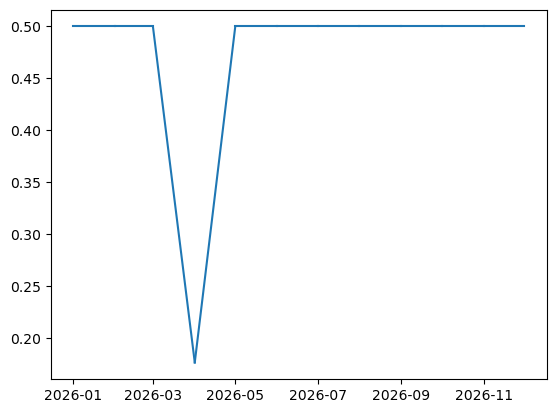

In [79]:
for i in range(11):
    x = pd.to_datetime([f"{2026}-{i+1:02d}-01", f"{2026}-{i+2:02d}-01"])
    plt.plot(x, out[0][1][i:i+2], color="C0")

In [91]:
out[1]

TIMESTAMP
2026-03-26 14:30:00    2
2026-03-26 15:00:00    2
2026-03-26 15:30:00    2
2026-03-26 16:00:00    2
2026-03-26 16:30:00    2
                      ..
2026-04-20 22:00:00    2
2026-04-20 22:30:00    2
2026-04-20 23:00:00    2
2026-04-20 23:30:00    2
2026-04-21 00:00:00    2
Name: USTAR, Length: 1219, dtype: int64

In [92]:
out[1].sum(), out[1].shape

(np.int64(1304), (1219,))

/var/folders/h1/hhwj_15n5pjc0cht5mmph_y40000gn/T/ipykernel_55789/2667893544.py:12: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  plt.plot(x, [out[0][1][i], out[0][1][i]], color="C0")


(np.float64(20542.0), np.float64(20545.0))

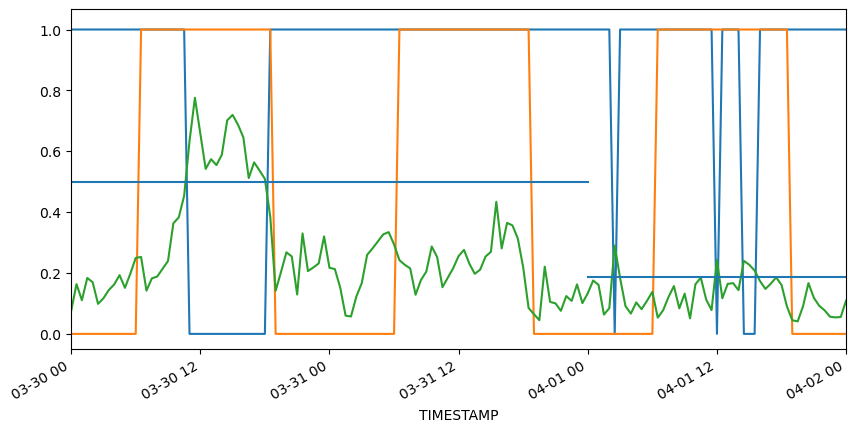

In [67]:
import matplotlib.pyplot as plt
(out[1]/2).plot(figsize=(10, 5))
# df["NEE"].plot()
df_isday.astype(int)["isday"].plot()
df["USTAR"].plot()

for i in range(12):
    try:
        x = pd.to_datetime([f"{2026}-{i+1:02d}-01", f"{2026}-{i+2:02d}-01"])
    except ValueError:
        x = pd.to_datetime([f"{2026}-{i+1:02d}-01", f"{2027}-01-01"])
    plt.plot(x, [out[0][1][i], out[0][1][i]], color="C0")
# plt.axhline(out[0][0], linewidth=1.5, color='r')
# 
plt.xlim(pd.to_datetime("2026-03-30"), pd.to_datetime("2026-04-02"))